# Fase 02 : Análisis estadístico y descriptivo
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Septiembre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Descripción de los datos con los que se va a trabajar

* **Fase del Proyecto:** Segunda fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [69]:
import polars as pl
import polars.selectors as cs
import s_01_functions as fn_01
from pyprojroot import here

<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

Carga de datos limpios

In [70]:
df_01 = pl.read_parquet(source = here()/'01_cleaned_data'/'df_01.parquet')
df_01.glimpse()

Rows: 964207
Columns: 11
$ bottle_volume_ml   <cat> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name      <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc            <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no            <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on        <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack               <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ period_ordered_on  <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ product_code       <str>

<h3 style="color:#05856d">3. Análisis descriptivo</h3>
<hr>

<h4 style="color:#05856d">3.1. Variables categóricas</h4>

In [71]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 5
$ bottle_volume_ml  <cat> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ store_no          <cat> 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296

Rows: 964207
Columns: 5
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026

<h5 style="font-weight: bold">Categoría del producto</h5>

Cantidad de órdenes o pedidos

In [72]:
df_01.\
    get_column('category_name').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

category_name,count_0,ptc_0
cat,u32,f64
"""AMERICAN VODKAS""",150163,0.155737
"""CANADIAN WHISKIES""",94229,0.097727
"""STRAIGHT BOURBON WHISKIES""",79556,0.082509
"""WHISKEY LIQUEUR""",72930,0.075637
"""100% AGAVE TEQUILA""",56061,0.058142
…,…,…
"""NEUTRAL GRAIN SPIRITS""",1425,0.001478
"""MEZCAL""",1116,0.001157
"""SPECIAL ORDER ITEMS""",328,0.00034


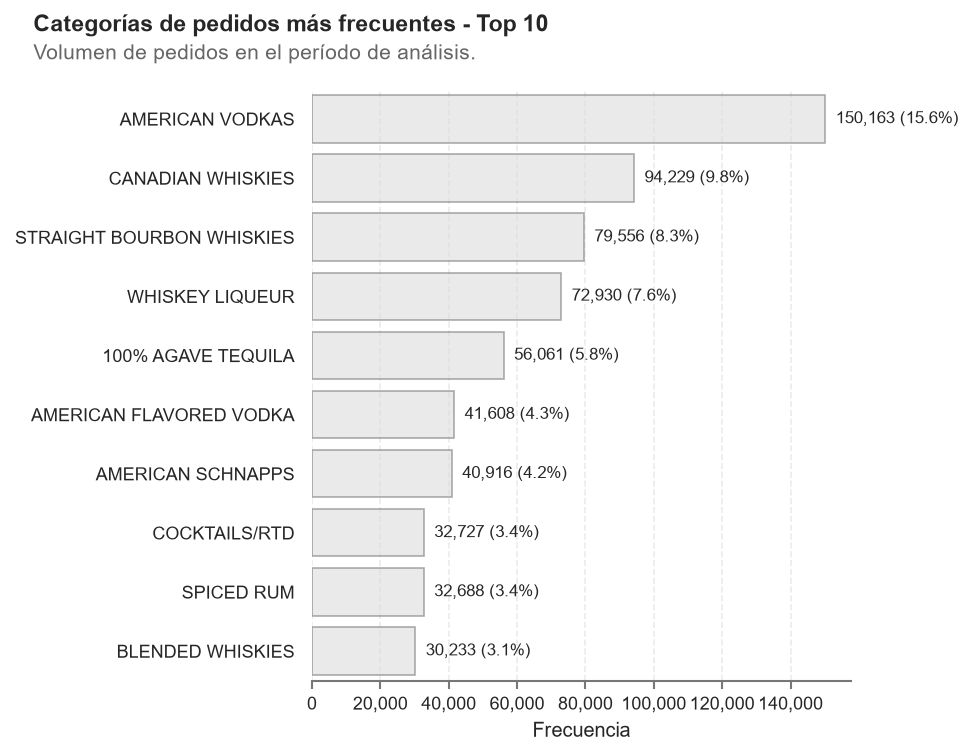

Guardado como: "s_04_01_top_10_categorias_pedidos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_01_top_10_categorias_pedidos.png')

In [73]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    calculate_param = 'count_',
    top_param = 10,
    suptitle_param = 'Categorías de pedidos más frecuentes - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_01_top_10_categorias_pedidos.png',
    show_param = True )

Cantidad demandada de botellas

In [74]:
df_01.\
    group_by('category_name').\
    agg(pl.sum('sales_bottles').alias('total_bottles')).\
    with_columns((pl.col('total_bottles') / pl.sum('total_bottles')).alias('ptc_0')).\
    sort( by = ['total_bottles'], descending = [True]) 

category_name,total_bottles,ptc_0
cat,i64,f64
"""AMERICAN VODKAS""",2549586,0.215371
"""WHISKEY LIQUEUR""",1893698,0.159966
"""CANADIAN WHISKIES""",1075720,0.090869
"""STRAIGHT BOURBON WHISKIES""",672149,0.056778
"""SPICED RUM""",514853,0.043491
…,…,…
"""AGED DARK RUM""",15718,0.001328
"""NEUTRAL GRAIN SPIRITS""",10206,0.000862
"""MEZCAL""",6203,0.000524


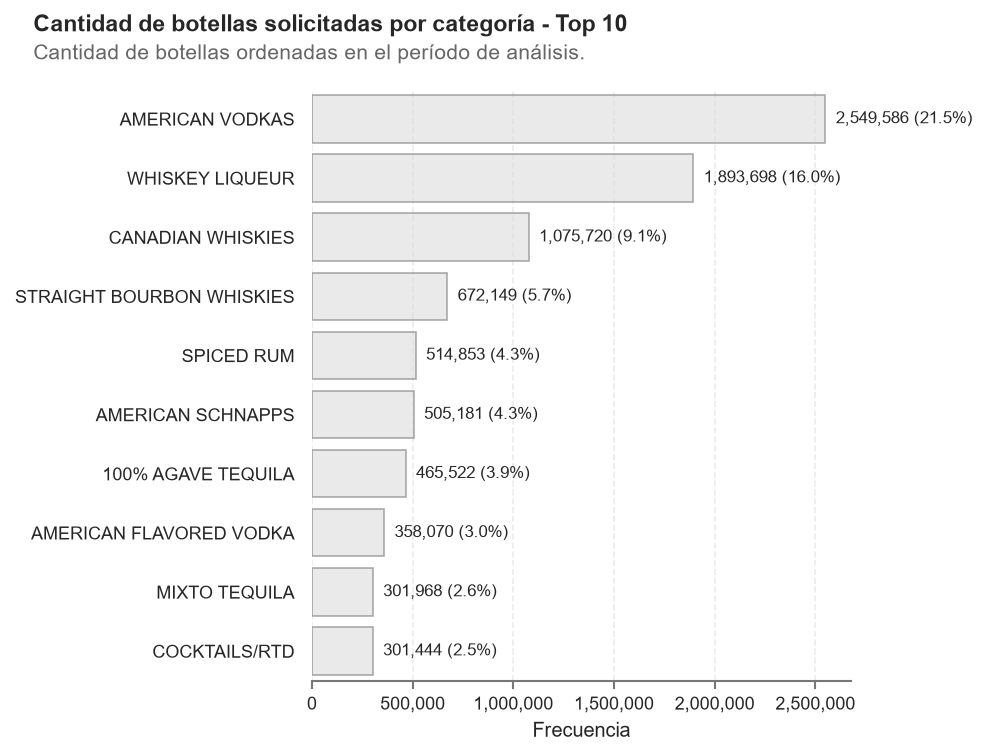

Guardado como: "s_04_02_top_10_categorias_botellas.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_02_top_10_categorias_botellas.png')

In [75]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    calculate_param = 'sum_bottles',
    top_param = 10,
    suptitle_param = 'Cantidad de botellas solicitadas por categoría - Top 10',
    text_param = 'Cantidad de botellas ordenadas en el período de análisis.',
    file_param = 's_04_02_top_10_categorias_botellas.png',
    show_param = True )

<h5 style="font-weight: bold">Descripción del producto</h5>

In [76]:
df_01.\
    get_column('im_desc').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

im_desc,count_0,ptc_0
cat,u32,f64
"""TITOS HANDMADE VODKA""",32326,0.033526
"""FIREBALL CINNAMON WHISKEY""",23670,0.024549
"""BLACK VELVET""",23216,0.024078
"""HAWKEYE VODKA""",21414,0.022209
"""FIREBALL CINNAMON WHISKEY MINI…",13497,0.013998
…,…,…
"""ANGOSTURA 5YR GOLD RUM""",1,0.000001
"""HA OLD FORESTER SINGLE BARREL …",1,0.000001
"""CM OBTAINIUM BLENDED WHISKEY""",1,0.000001


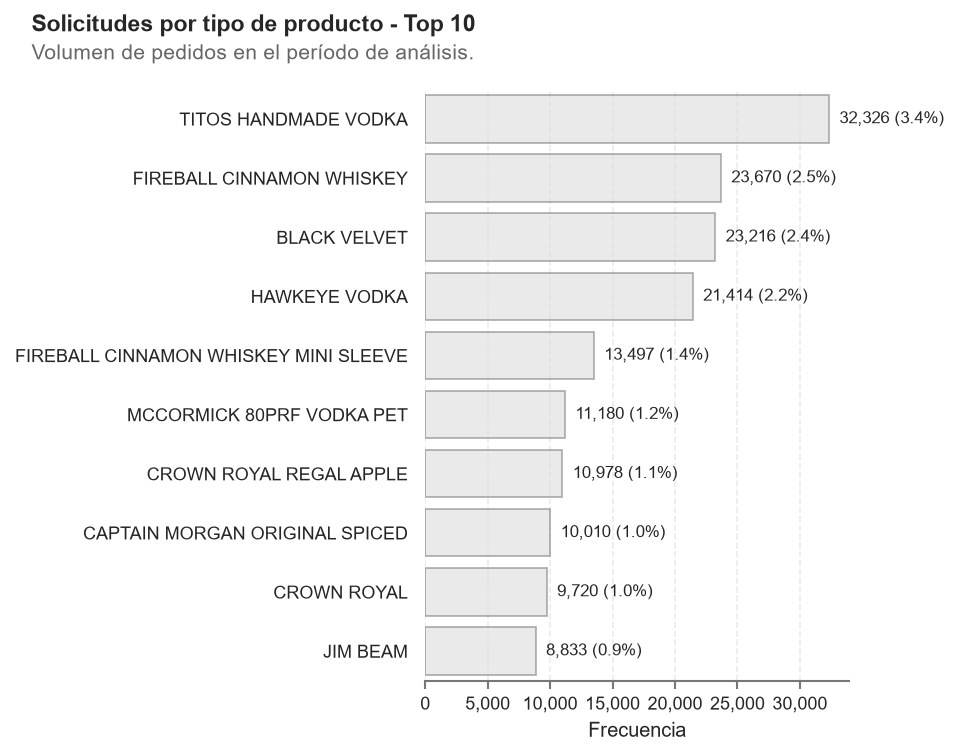

Guardado como: "s_04_03_top_10_productos_pedidos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_03_top_10_productos_pedidos.png')

In [77]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'im_desc',
    calculate_param = 'count_',
    top_param = 10,
    suptitle_param = 'Solicitudes por tipo de producto - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_03_top_10_productos_pedidos.png',
    show_param = True )

In [78]:
df_01.\
    group_by('im_desc').\
    agg(pl.sum('sales_bottles').alias('total_bottles')).\
    with_columns((pl.col('total_bottles') / pl.sum('total_bottles')).alias('ptc_0')).\
    sort( by = ['total_bottles'], descending = [True]) 

im_desc,total_bottles,ptc_0
cat,i64,f64
"""FIREBALL CINNAMON WHISKEY""",1214207,0.102567
"""TITOS HANDMADE VODKA""",658527,0.055628
"""BLACK VELVET""",378380,0.031963
"""FIREBALL CINNAMON WHISKEY MINI…",361522,0.030539
"""HAWKEYE VODKA""",306593,0.025899
…,…,…
"""OLE SMOKY CINNAMON WHISKEY DIS…",1,8.4473e-8
"""HIGH WEST BOURBON""",1,8.4473e-8
"""TOWN BRANCH OVERPROOF""",1,8.4473e-8


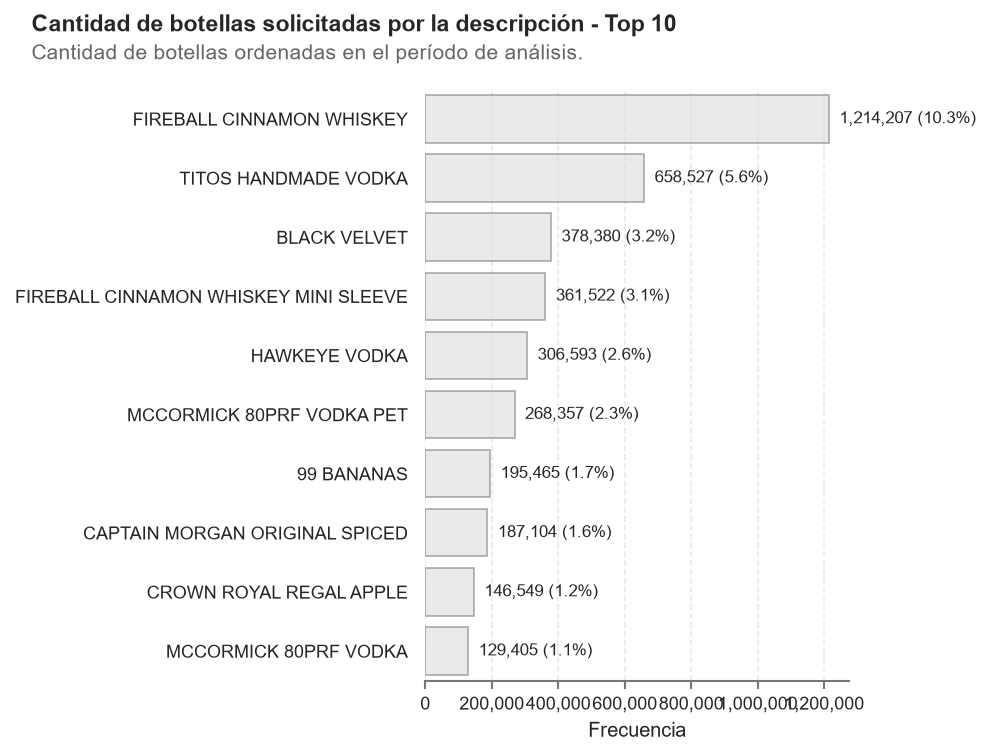

Guardado como: "s_04_04_top_10_productos_botellas.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_04_top_10_productos_botellas.png')

In [79]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'im_desc',
    calculate_param = 'sum_bottles',
    top_param = 10,
    suptitle_param = 'Cantidad de botellas solicitadas por la descripción - Top 10',
    text_param = 'Cantidad de botellas ordenadas en el período de análisis.',
    file_param = 's_04_04_top_10_productos_botellas.png',
    show_param = True )

<h5 style="font-weight: bold">Volumen de botellas</h5>

Aunque medir mililitros puede conducir a variables continuas, las botellas almacenan (en general) volúmenes estándar. Esta característica lleva a que esta variable sea tratada de forma categórica para el caso de estudio.

Dentro del dataframe existen 13 tipos de botellas diferencias por su tamaño.

In [80]:
df_01.get_column('bottle_volume_ml').n_unique()

13

In [32]:
( df_01
    .group_by('bottle_volume_ml')
    .agg(pl.sum('sales_bottles'))
    .sort( by = ['sales_bottles'], descending = [True] )
    .with_columns( (pl.col('sales_bottles') / pl.sum('sales_bottles')).alias('ptc_0') )
    )

bottle_volume_ml,sales_bottles,ptc_0
str,i64,f64
"""750.0""",3323493,0.280745
"""1750.0""",1937542,0.163669
"""375.0""",1742841,0.147223
"""1000.0""",1622324,0.137042
"""100.0""",1527166,0.129004
…,…,…
"""25.0""",1458,0.000123
"""20.0""",809,0.000068
"""3000.0""",222,0.000019


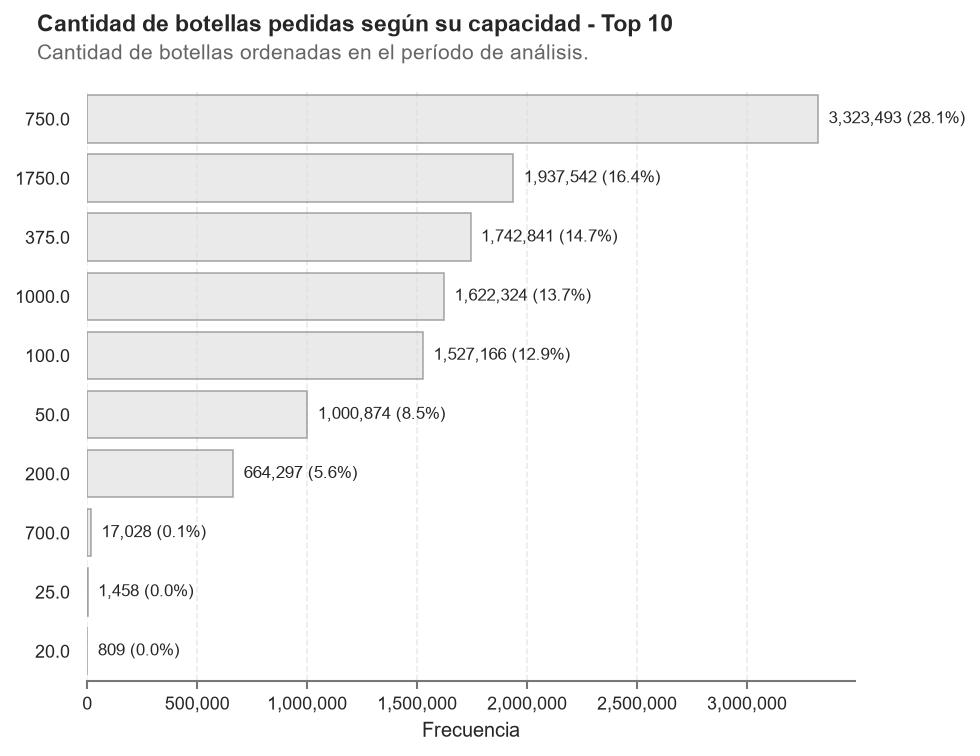

Guardado como: "s_04_04_bottle_volume_ml.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_04_bottle_volume_ml.png')

In [33]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'bottle_volume_ml',
    calculate_param = 'sum_bottles',
    top_param = 10,
    suptitle_param = 'Cantidad de botellas pedidas según su capacidad - Top 10',
    text_param = 'Cantidad de botellas ordenadas en el período de análisis.',
    file_param = 's_04_04_bottle_volume_ml.png',
    show_param = True )

<h4 style="color:#05856d">3.2. Variables numéricas y de fecha</h4>

¿Cuáles son las variables numéricas y de fecha disponibles?

In [34]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 5
$ bottle_volume_ml  <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ store_no          <cat> 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296

Rows: 964207
Columns: 5
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-

¿Cuál es el espacio de tiempo en el cual se capturaron los datos?

In [35]:
print(f"Fecha más antigua disponible: {df_01.get_column('ordered_on').min()}")
print(f"Fecha más actual disponible: {df_01.get_column('ordered_on').max()}")

Fecha más antigua disponible: 2026-01-01
Fecha más actual disponible: 2026-05-30


**¿Cuál es la distribución de las botellas ordenadas por pedido?**

Para dibujar la distribución primero es necesario agrupar la cantidad de botellas compradas por día

Los pedidos manejan altos volúmenes de demanda. Existen, po lo menos 70 días, donde se ordenaron más de 100,000 botellas

In [172]:
df_01.group_by('ordered_on').agg(pl.sum('sales_bottles')).select('sales_bottles').describe()

statistic,sales_bottles
str,f64
"""count""",116.0
"""null_count""",0.0
"""mean""",102052.922414
"""std""",32359.577634
"""min""",96.0
"""25%""",95102.0
"""50%""",109199.0
"""75%""",119795.0
"""max""",170571.0


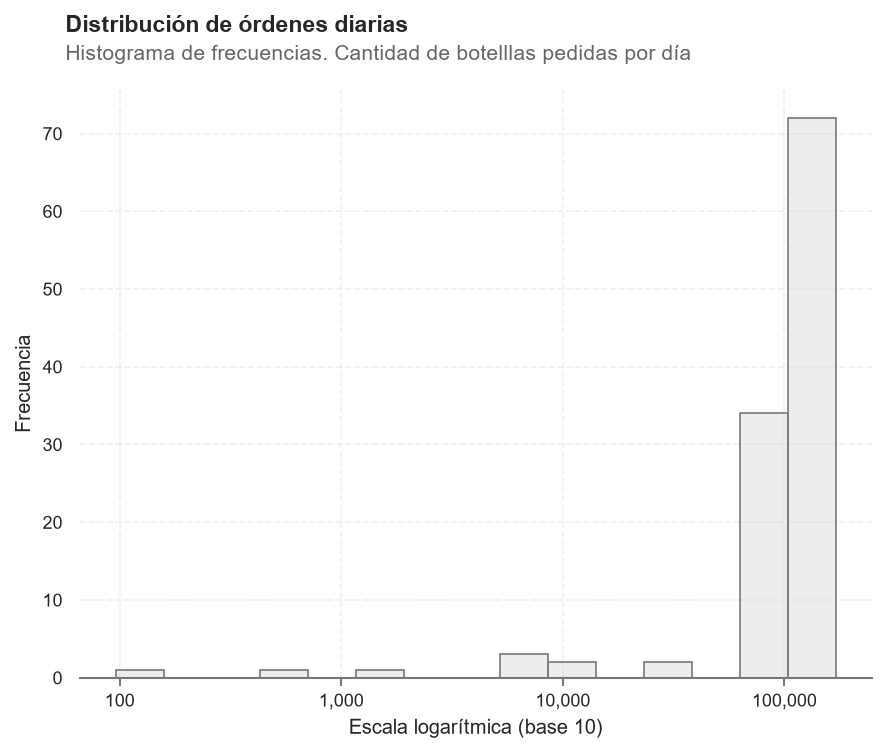

Guardado como: "s_04_05_hist_botellas.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_05_hist_botellas.png')

In [36]:
fn_01.plot_cat_function_02(
    df_param = df_01.group_by('ordered_on').agg(pl.sum('sales_bottles')),
    df_var = 'sales_bottles',
    bins_param = 15,
    suptitle_param = 'Distribución de órdenes diarias',
    text_param = 'Histograma de frecuencias. Cantidad de botelllas pedidas por día',
    file_param = 's_04_05_hist_botellas.png',
    show_param = True)

**¿Cuál es la distribución de los ingresos por pedido diario?**

Para dibujar la distribución primero es necesario agrupar la cantidad de ingresos por día

Al menos en 50 días se generaron ingresos por encima de un millón de dólares

In [37]:
df_01.group_by('ordered_on').agg(pl.sum('sales_dollars')).select('sales_dollars').describe()

statistic,sales_dollars
str,f64
"""count""",116.0
"""null_count""",0.0
"""mean""",1.3891e6
"""std""",450554.135384
"""min""",3167.04
"""25%""",1.2905e6
"""50%""",1.4650e6
"""75%""",1.6522e6
"""max""",2.2593e6


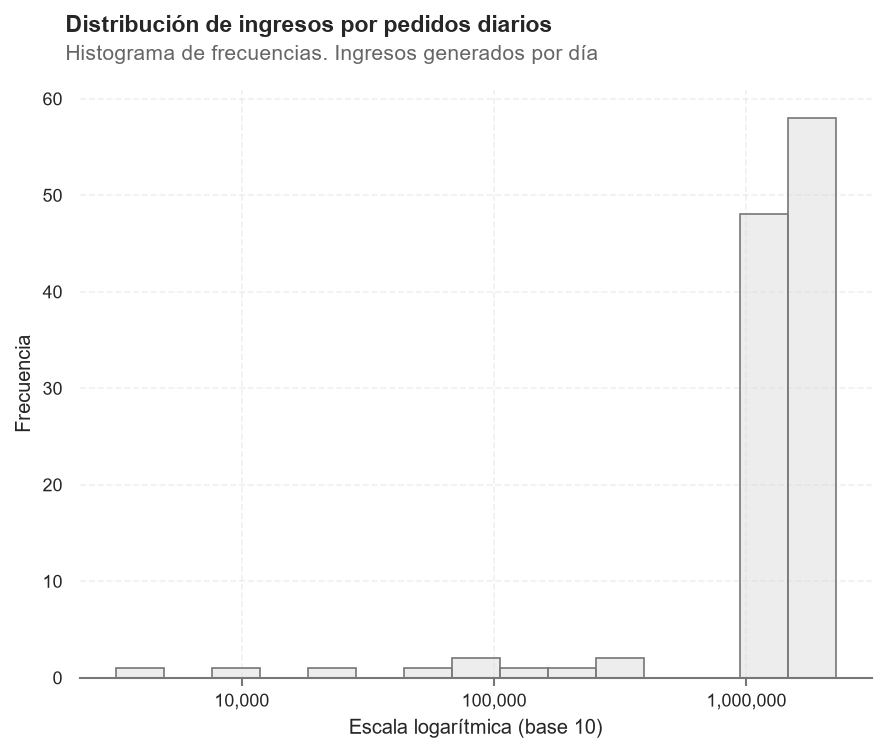

Guardado como: "s_04_06_hist_ingresos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_06_hist_ingresos.png')

In [38]:
fn_01.plot_cat_function_02(
    df_param = df_01.group_by('ordered_on').agg(pl.sum('sales_dollars')),
    df_var = 'sales_dollars',
    bins_param = 15,
    suptitle_param = 'Distribución de ingresos por pedidos diarios',
    text_param = 'Histograma de frecuencias. Ingresos generados por día',
    file_param = 's_04_06_hist_ingresos.png',
    show_param = True)

<h3 style="color:#05856d">4. Análisis relacional</h3>
<hr>

¿Cuáles son las variables numéricas y de fecha disponibles?

In [39]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 5
$ bottle_volume_ml  <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ store_no          <cat> 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296

Rows: 964207
Columns: 5
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-

<h4 style="color:#05856d">4.1. Asociaciones</h4>

Se busca analizar el nivel de asociación basado en la frecuencia u ocurrencia.

**¿Exite una posible asociación entre el tipo de presentación (botella) y alguna categoría de acuerdo con la cantidad de producto (botellas) solicitado?**

In [ ]:
aux = ( df_01
    .group_by('category_name')
    .agg(pl.sum('sales_bottles').alias('total_bottles'))
    .filter( pl.col('total_bottles').rank(method = 'dense', descending = True) <= 3 )
    .sort( by = ['total_bottles'], descending = [True])
    )

print(aux)

( df_01
    .filter(pl.col('category_name').is_in(aux['category_name'].implode()))
    .group_by(['category_name', 'bottle_volume_ml'])
    .agg(pl.sum('sales_bottles'))
    .with_columns( pl.col('bottle_volume_ml').cast(dtype = pl.Float32()))
    .sort(['bottle_volume_ml','category_name'])
    .pivot(
        on = 'category_name',
        index = 'bottle_volume_ml',
        values = 'sales_bottles' )
    .fill_null(0)
    )



shape: (3, 2)
┌───────────────────┬───────────────┐
│ category_name     ┆ total_bottles │
│ ---               ┆ ---           │
│ cat               ┆ i64           │
╞═══════════════════╪═══════════════╡
│ AMERICAN VODKAS   ┆ 2549586       │
│ WHISKEY LIQUEUR   ┆ 1893698       │
│ CANADIAN WHISKIES ┆ 1075720       │
└───────────────────┴───────────────┘


bottle_volume_ml,AMERICAN VODKAS,CANADIAN WHISKIES,WHISKEY LIQUEUR
f32,i64,i64,i64
50.0,126048,66706,447298
100.0,19879,5925,1013614
200.0,200775,79374,122372
375.0,660649,202135,119248
700.0,0,0,963
750.0,495547,289376,106744
1000.0,394976,116765,35663
1750.0,651712,315439,47796


<h4 style="color:#05856d">4.2. Correlaciones</h4>

<h4 style="color:#05856d">4.3. Comparaciones</h4>

<h3 style="color:#05856d">5. Selección del caso de modelamiento</h3>
<hr>

**¿Cuál es el producto que genera más ingresos y que tiene más movimientos?**

De acuerdo al desempeño de los productos agrupados por tienda. El "mejor producto" en términos de ingreso y movimientos es atribuido al código "PRD_001358"

In [32]:
analysis_01 = (
    df_01
    .group_by(['product_code','store_no'])
    .agg(

        # 1. ¿Qué categorías de productos están involucrados?
        pl.col('category_name').unique().str.join(', '),

        # 2. ¿Cuántas botellas se han vendido en la historia de este producto?
        pl.sum('sales_bottles').alias('volumen_botellas'),

        # 3. Ingresos genereados por la venta de botellas (expresado en miles)
        (pl.sum('sales_dollars')/1000).alias('sales_miles'),
        
        # 4. ¿En cuántos días únicos alguien compró al menos 1 botella?
        pl.n_unique('ordered_on').alias('frecuencia_dias_demanda'),

        pl.col('ordered_on').n_unique().cut(
            breaks = [10,20,30,40],
            labels = [ '0-10 días', '10-20 días', '20-30 días', '30-40 días', 'más de 40 días'],
            left_closed = False ).alias('frecuencia_dias_demanda_cat') )
    
    # Ordenar por los que tienen demanda más constante, y luego por volumen
    .sort(['frecuencia_dias_demanda', 'sales_miles'], descending = [True, True])
)

print(f"Existen {df_01.n_unique(subset = ['product_code'])} productos únicos en el dataset.")
print(analysis_01.shape)
analysis_01.head()

Existen 4047 productos únicos en el dataset.
(401309, 7)


product_code,store_no,category_name,volumen_botellas,sales_miles,frecuencia_dias_demanda,frecuencia_dias_demanda_cat
str,cat,str,i64,f64,u32,enum
"""PRD_001358""","""4829""","""AMERICAN VODKAS""",22428,443.17184,46,"""más de 40 días"""
"""PRD_000180""","""4829""","""CANADIAN WHISKIES""",4152,127.62552,46,"""más de 40 días"""
"""PRD_001246""","""4829""","""AMERICAN VODKAS""",4788,34.18108,45,"""más de 40 días"""
"""PRD_000532""","""4829""","""STRAIGHT BOURBON WHISKIES""",2664,89.91,44,"""más de 40 días"""
"""PRD_001136""","""4829""","""IMPORTED VODKAS""",1884,53.694,44,"""más de 40 días"""


La mayoría de los productos se suelen pedir en pocas ocasiones, es decir, las órdenens suelen renovarse antes de los 10 días.

In [9]:
analysis_01.get_column('frecuencia_dias_demanda_cat').value_counts().sort(['frecuencia_dias_demanda_cat']).show()

shape: (5, 2)
┌─────────────────────────────┬────────┐
│ frecuencia_dias_demanda_cat ┆ count  │
│ ---                         ┆ ---    │
│ enum                        ┆ u32    │
╞═════════════════════════════╪════════╡
│ 0-10 días                   ┆ 393052 │
│ 10-20 días                  ┆ 7679   │
│ 20-30 días                  ┆ 427    │
│ 30-40 días                  ┆ 120    │
│ más de 40 días              ┆ 31     │
└─────────────────────────────┴────────┘


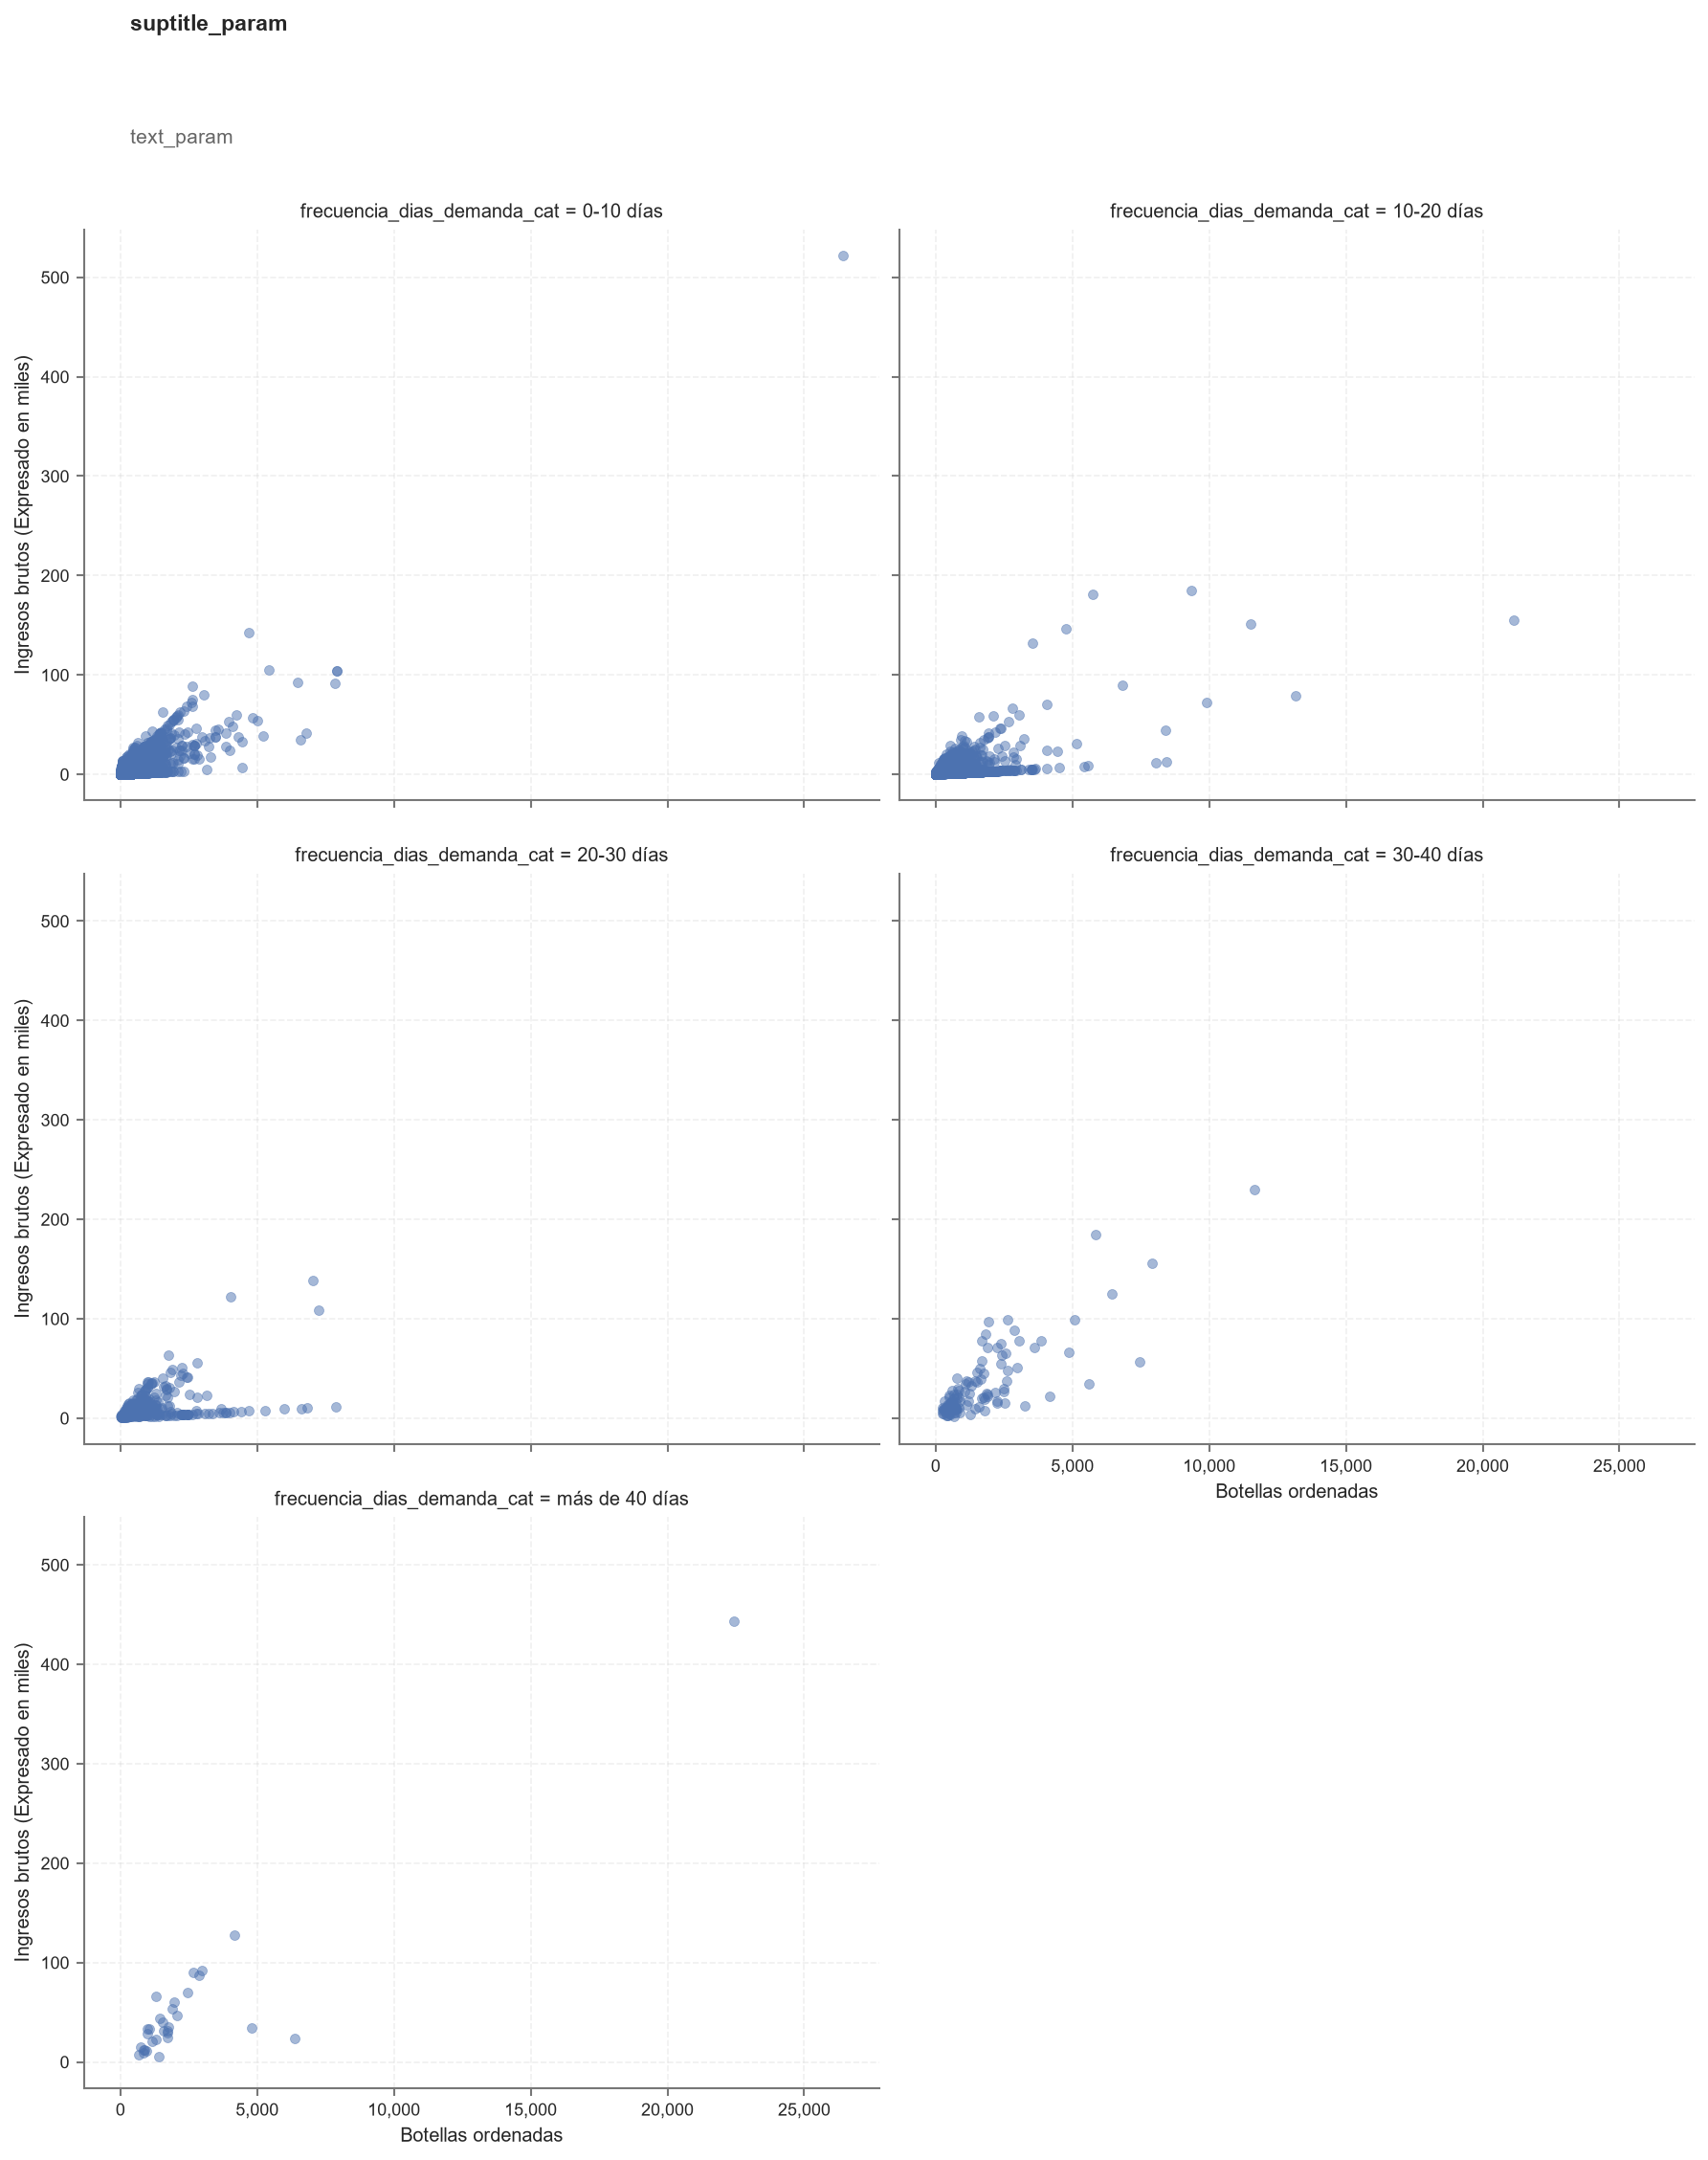

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import ticker

sns.set_theme( context = 'paper',
               style = 'white',
               rc = {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.3})

g = sns.relplot(
    data = analysis_01,
    x = 'volumen_botellas',
    y = 'sales_miles',
    #hue = 'frecuencia_dias_demanda_cat',
    edgecolor = None,
    height = 5,
    aspect = 1.2,
    alpha = 0.5,
    col = 'frecuencia_dias_demanda_cat',
    col_wrap = 2
    )

g.despine(left = False, bottom = False)
g.set_axis_labels( x_var = 'Botellas ordenadas', y_var = 'Ingresos brutos (Expresado en miles)' )
g.figure.subplots_adjust(top = 0.90)

g.figure.suptitle(
    t = 'suptitle_param',
    x = 0.08,
    y = 1.00,
    ha = 'left',
    weight = 'bold',
    size = 11 )

g.figure.text(
    s = 'text_param',
    x = 0.08,
    y = 0.94,
    ha = 'left',
    fontsize = 10,
    color = '#666666' )

for ax in g.axes.flat:
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.spines['bottom'].set_color('#777777')
    ax.spines['left'].set_color('#777777')
    ax.tick_params( axis = 'both', length = 4, color = '#777777',
                    bottom = True, left = True )

plt.show()


**Distribución de la tienda y producto seleccionado**

Colocar la distribución del caso seleccionado

<h4 style="color:#05856d">5.1. Preparación del caso seleccionado</h4>

In [33]:
( df_01
    .filter(
        (pl.col('product_code') == 'PRD_001358') & 
        (pl.col('store_no') == '4829') )
    #.select(pl.col('sales_bottles').sum())
    .glimpse()
    )

Rows: 59
Columns: 11
$ bottle_volume_ml   <str> '1000.0', '1000.0', '1000.0', '1000.0', '1000.0', '1000.0', '1000.0', '1000.0', '1000.0', '1000.0'
$ category_name      <cat> AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS, AMERICAN VODKAS
$ im_desc            <cat> TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA, TITOS HANDMADE VODKA
$ item_no            <i64> 38177, 38177, 38177, 38177, 38177, 38177, 38177, 38177, 38177, 38177
$ ordered_on        <date> 2026-02-19, 2026-02-23, 2026-02-23, 2026-02-26, 2026-03-02, 2026-03-02, 2026-03-05, 2026-03-09, 2026-04-09, 2026-04-13
$ pack               <i64> 12, 12, 12, 12, 12, 12, 12, 12, 12, 12
$ period_ordered_on  <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-03, 2026-03, 2026-03, 2026-03, 2026